In [1]:
import numpy as np
import pandas as pd

import os
import glob
import matplotlib.pyplot as plt

from tqdm import tqdm

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision.io as io
import torchvision.models as models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

In [36]:
import zipfile
import os
from tqdm import tqdm

# 실제 imgs.zip 파일 경로로 수정
zip_path = '/content/drive/MyDrive/imgs.zip'
extract_path = '/content/drive/MyDrive/data'

# 압축 파일 내에서 train/ 폴더 아래에 있는 파일만 필터링해서 압축을 풉니다.
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    # 압축 파일 내 모든 파일 목록 가져오기
    all_files = zip_ref.namelist()

# 'train/' 혹은 'imgs/train/' 등 train 경로를 포함하는 파일만 필터링
train_files = [f for f in all_files if 'train/' in f]

if train_files:
    print(f"총 {len(train_files)}개의 train 관련 파일을 압축 해제 중입니다...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        for file in tqdm(train_files):
            zip_ref.extract(file, path=extract_path)
    print("압축 해제가 완료되었습니다!")
else:
    print("압축 파일 내에서 'train/' 경로를 찾을 수 없습니다. 파일 목록 중 일부를 출력합니다:")
    print(all_files[:10])

총 22424개의 train 관련 파일을 압축 해제 중입니다...


100%|██████████| 22424/22424 [00:40<00:00, 550.26it/s]

압축 해제가 완료되었습니다!


In [5]:
train_path = '/content/drive/MyDrive/data/train'
for folder in glob.glob(train_path+'/*'):
  folder_name = folder.split('/')[-1]
  print(f'{folder_name}:{len(os.listdir(folder))} images')

c0:2489 images
c1:2267 images
c2:2317 images
c3:2346 images
c4:2326 images
c5:2312 images
c6:2325 images
c7:2002 images
c8:1911 images
c9:2129 images


In [6]:
classes = {
    'c0': 'safe driving',
    'c1': 'texting - right',
    'c2': 'talking on the phone - right',
    'c3': 'texting - left',
    'c4': 'talking on the phone - left',
    'c5': 'operating the radio',
    'c6': 'drinking',
    'c7': 'reaching behind',
    'c8': 'hair and makeup',
    'c9': 'talking to passenger'
}

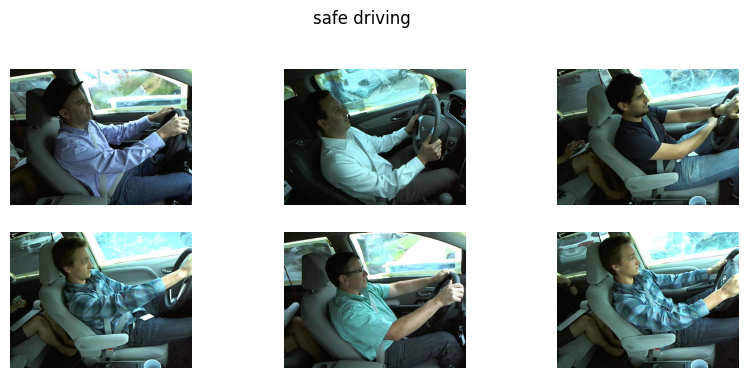

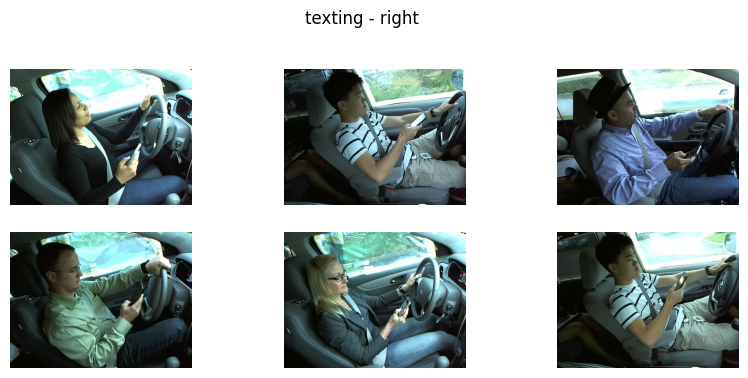

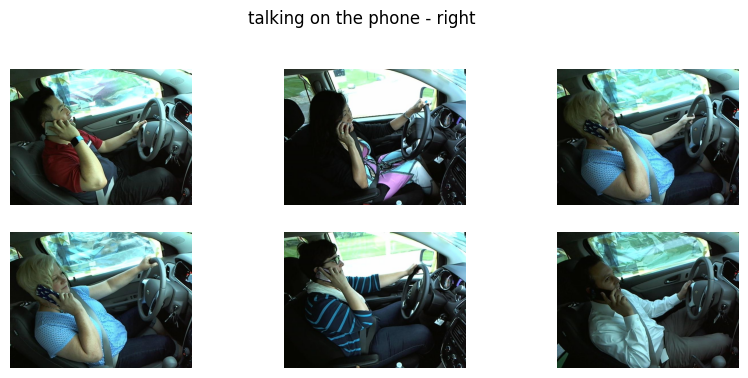

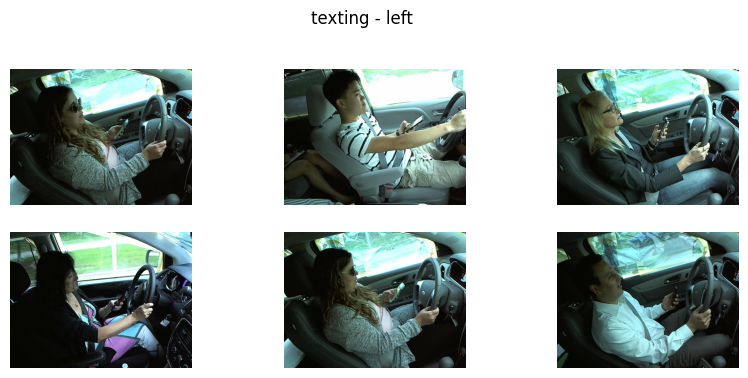

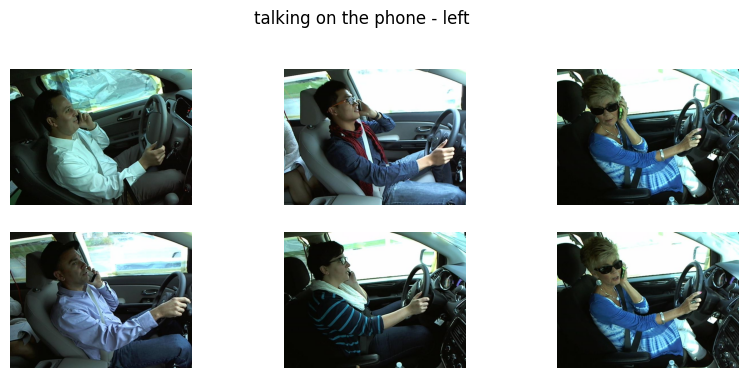

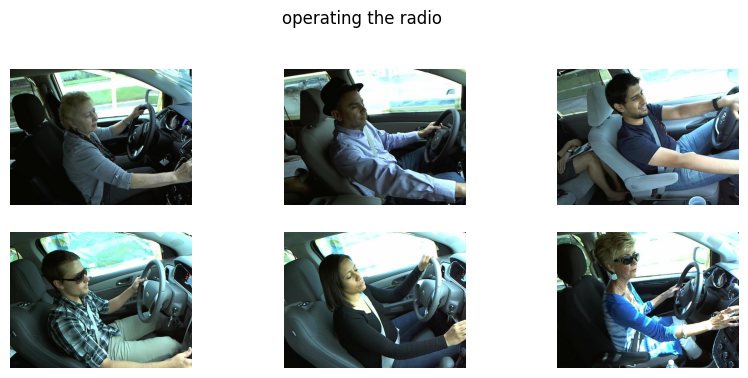

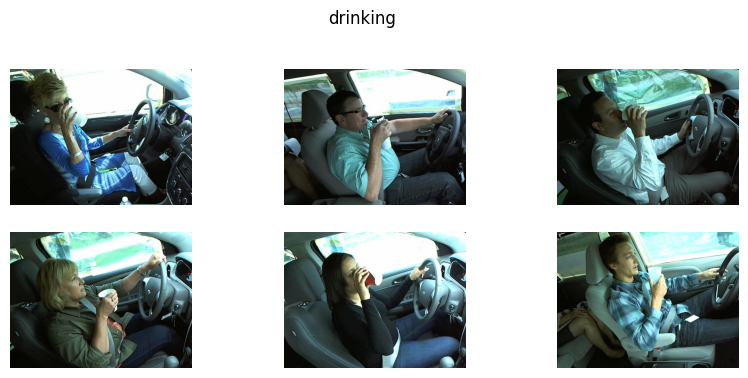

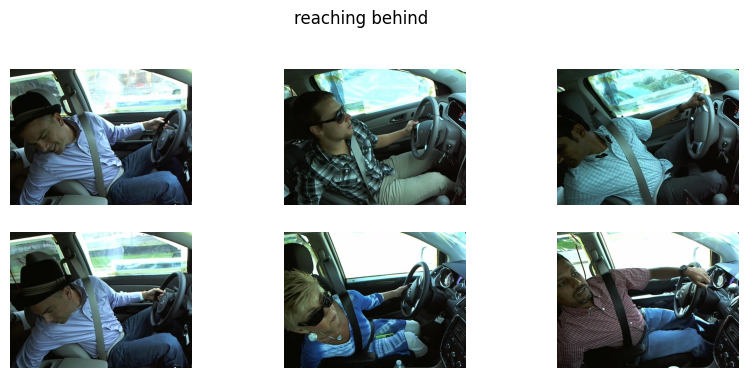

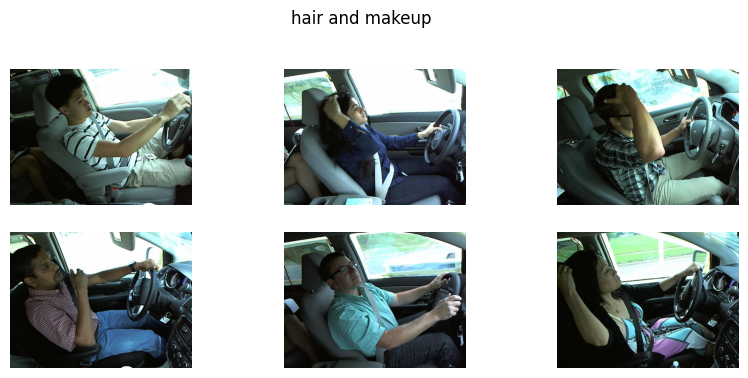

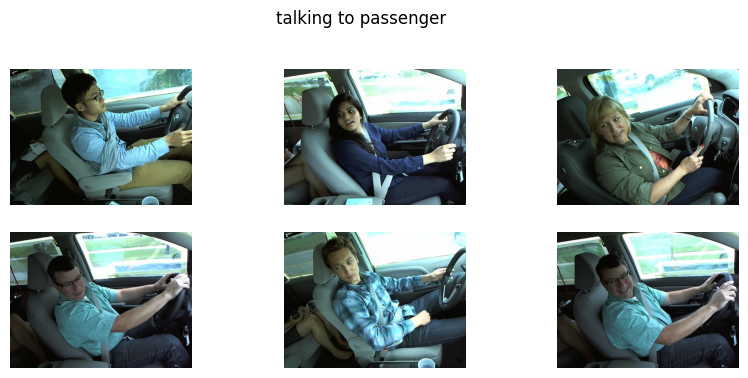

In [7]:
def show_images(folder_path, num):
  """
  Description:
  Display a random selection of images from the specified folder path.

  Parameters:
  - folder_path(str): The path to the folder containing the images.
  - num(int): The number of images to display.

  Returns:
  None
  """

  images = glob.glob(folder_path+'/*')
  selected_images = np.random.choice(images, num, replace=False)

  fig = plt.figure(figsize=(10,6))
  columns = 3
  rows = (len(selected_images)//columns)+1
  for i, image_file in enumerate(selected_images):
    img = plt.imread(image_file)
    ax = fig.add_subplot(rows, columns, i+1)
    ax.imshow(img)
    ax.axis('off')
  class_ = folder_path.split('/')[-1]
  plt.suptitle(classes[class_])
  plt.show()

for folder in glob.glob(train_path+'/*'):
  if os.path.isdir(folder):
    show_images(folder, 6)

In [8]:
img_path = '/content/drive/MyDrive/data/train/c1/img_100021.jpg'
img = io.read_image(img_path)
img.shape

torch.Size([3, 480, 640])

## BaseLine Dense Model

In [9]:
class BaselineDenseModel(nn.Module):
  def __init__(self, input_size, num_classes):
    super(BaselineDenseModel, self).__init__()
    self.fc1 = nn.Linear(input_size, 256)
    self.fc2 = nn.Linear(256, 128)
    self.fc3 = nn.Linear(128, 64)
    self.fc4 = nn.Linear(64, 32)
    self.fc5 = nn.Linear(32, num_classes)
    self.relu = nn.ReLU()
    self.softmax = nn.Softmax(dim=1)


  def forward(self, x):
    x = x.view(x.size(0), -1) #flatten the input
    x = self.relu(self.fc1(x))
    x = self.relu(self.fc2(x))
    x = self.relu(self.fc3(x))
    x = self.relu(self.fc4(x))
    x = self.fc5(x)
    return self.softmax(x)


input_size = 480*640*3
num_classes = 10

model = BaselineDenseModel(input_size, num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

In [10]:
train_transform = transforms.Compose([
    transforms.Resize((480, 640)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1), scale=(1.0, 1.2)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((480, 640)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [11]:
dataset = datasets.ImageFolder(root=train_path, transform=train_transform)

In [12]:
dataset

Dataset ImageFolder
    Number of datapoints: 22424
    Root location: /content/drive/MyDrive/data/train
    StandardTransform
Transform: Compose(
               Resize(size=(480, 640), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
               RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), scale=(1.0, 1.2))
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )

In [13]:
class2idx = dataset.class_to_idx
class_indices = {v:k for k,v in class2idx.items()}
class_indices

{0: 'c0',
 1: 'c1',
 2: 'c2',
 3: 'c3',
 4: 'c4',
 5: 'c5',
 6: 'c6',
 7: 'c7',
 8: 'c8',
 9: 'c9'}

In [14]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [15]:
#Split the dataset into training and validation sets
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [16]:
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = test_transform

In [17]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [18]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [19]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, device='cuda'):
    """
    Description:
        Train the given model using the provided data loaders and optimization parameters.

    Parameters:
        - model (torch.nn.Module): The neural network model to train.
        - train_loader (torch.utils.data.DataLoader): DataLoader for training data.
        - val_loader (torch.utils.data.DataLoader): DataLoader for validation data.
        - criterion (torch.nn.Module): The loss function.
        - optimizer (torch.optim.Optimizer): The optimizer used for updating model parameters.
        - num_epochs (int): Number of training epochs (default: 10).
        - device (str): Device to run the training on (default: 'cuda').

    Returns:
        - model (torch.nn.Module): The trained model.
        - history (dict): A dictionary containing training history with keys:
            - 'train_loss': List of training losses for each epoch.
            - 'train_acc': List of training accuracies for each epoch.
            - 'val_loss': List of validation losses for each epoch.
            - 'val_acc': List of validation accuracies for each epoch.

    """

    model.to(device)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in tqdm(range(num_epochs)):
        # Training phase
        model.train()
        train_loss = 0.0
        correct_train = 0
        total_train_images = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, dim=1)
            correct_train += (predicted == labels).sum().item()
            total_train_images += labels.size(0)


        train_accuracy = 100 * correct_train / total_train_images
        avg_train_loss = train_loss / len(train_loader)

        # Validation phase
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val_images = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                correct_val += (predicted == labels).sum().item()
                total_val_images += labels.size(0)


        val_accuracy = 100 * correct_val / total_val_images
        avg_val_loss = val_loss / len(val_loader)

        # Print epoch statistics
        print(f"Epoch [{epoch+1}/{num_epochs}]\nTrain Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")

        # Save history
        history['train_loss'].append(avg_train_loss)
        history['train_acc'].append(train_accuracy)
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(val_accuracy)

    return model, history

In [20]:
def plot_performance(history):
    """
    Description:
        Plot the training and validation loss, as well as training and validation accuracy over epochs.

    Parameters:
        - history (dict): A dictionary containing training history with keys:
        - 'train_loss': List of training losses for each epoch.
        - 'train_acc': List of training accuracies for each epoch.
        - 'val_loss': List of validation losses for each epoch.
        - 'val_acc': List of validation accuracies for each epoch.

    Returns:
        None
    """

    epochs = range(1, len(history['train_loss']) + 1)

    #Plot loss
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss')
    plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    #Plot accuracy
    plt.subplot(1,2,2)
    plt.plot(epochs, history['train_acc'], 'b-', label = 'Training Accuracy')
    plt.plot(epochs, history['val_acc'], 'r-', label = 'Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy(%)')
    plt.legend()


    plt.tight_layout()
    plt.show()

##Baseline CNN

In [21]:
class BaselineCNN(nn.Module):
  def __init__(self, num_classes):
    super(BaselineCNN, self).__init__()
    self.conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=1, padding=1)
    self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)
    self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
    self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
    self.fc1 = nn.Linear(64*37*37, 512)
    self.fc2 = nn.Linear(512, num_classes)

  def forward(self, x):
    identity = torch.relu(self.conv(x))
    out = torch.relu(self.conv1(x))
    out = torch.relu(self.conv2(out))
    out = out + identity

    out = self.pool(self.pool(out))

    out = out.view(out.size(0), -1)
    out = torch.relu(self.fc1(out))
    out = self.fc2(out)
    return out

model = BaselineCNN(num_classes=10)

In [22]:
train_transform = transforms.Compose([
    transforms.Resize((150,150)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(1.0, 1.2)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [23]:
test_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [24]:
dataset = datasets.ImageFolder(root=train_path, transform=train_transform)

In [25]:
dataset

Dataset ImageFolder
    Number of datapoints: 22424
    Root location: /content/drive/MyDrive/data/train
    StandardTransform
Transform: Compose(
               Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
               RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), scale=(1.0, 1.2))
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )

In [26]:
class2idx = dataset.class_to_idx
class_indices = {v:k for k,v in class2idx.items()}
class_indices

{0: 'c0',
 1: 'c1',
 2: 'c2',
 3: 'c3',
 4: 'c4',
 5: 'c5',
 6: 'c6',
 7: 'c7',
 8: 'c8',
 9: 'c9'}

In [27]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [28]:
#Split the dataset into training and validation sets
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [29]:
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = test_transform

In [30]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size = batch_size, shuffle=False)

In [31]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

In [32]:
trained_model, history = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=6)

 17%|█▋        | 1/6 [00:56<04:40, 56.18s/it]

Epoch [1/6]
Train Loss: 1.5017, Train Acc: 81.23%, Val Loss: 0.1323, Val Acc: 96.61%


 33%|███▎      | 2/6 [01:50<03:40, 55.19s/it]

Epoch [2/6]
Train Loss: 0.0521, Train Acc: 98.68%, Val Loss: 0.0439, Val Acc: 98.97%


 50%|█████     | 3/6 [02:45<02:45, 55.11s/it]

...

Epoch [4/6]
Train Loss: 0.0295, Train Acc: 99.10%, Val Loss: 0.0905, Val Acc: 97.55%


 83%|████████▎ | 5/6 [04:34<00:54, 54.70s/it]

Epoch [5/6]
Train Loss: 0.0233, Train Acc: 99.25%, Val Loss: 0.0609, Val Acc: 98.68%


100%|██████████| 6/6 [05:28<00:00, 54.79s/it]

Epoch [6/6]
Train Loss: 0.0219, Train Acc: 99.33%, Val Loss: 0.0594, Val Acc: 98.71%


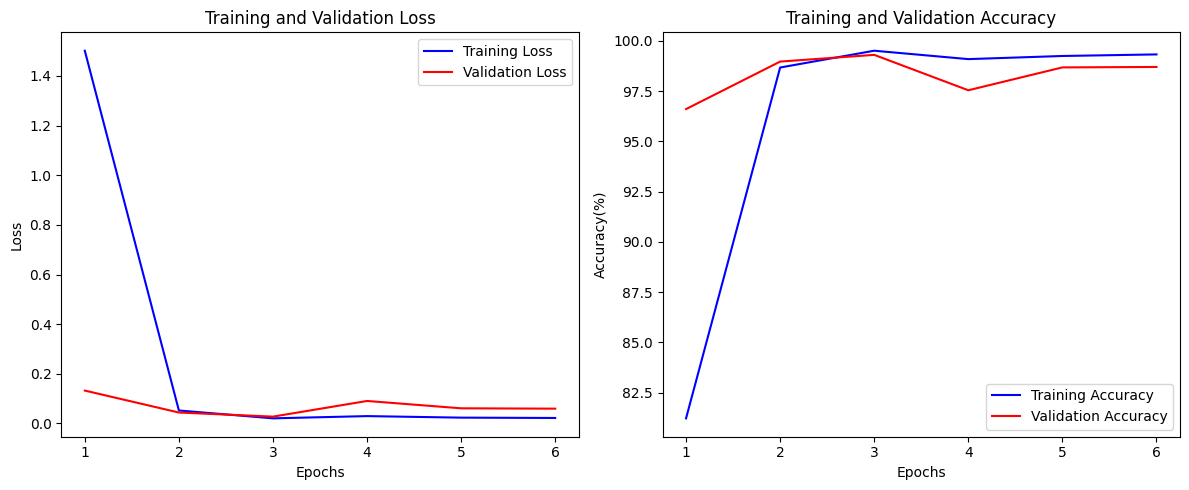

In [33]:
plot_performance(history)

##Test model on Test Data


In [48]:
from torch.utils.data import Dataset

class TestFolderDataset(Dataset):
  def __init__(self, paths, transform):
    self.paths = paths
    self.transform = transform

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, idx):
    image = Image.open(self.paths[idx])
    return self.transform(image)

def predict_folder(folder_path, model, batch_size=128):
  img_paths = glob.glob(folder_path+'/*')
  loader = DataLoader(TestFolderDataset(img_paths, test_transform),
                      batch_size=batch_size, shuffle=False, num_workers=2)

  probabilities_per_image = []
  model.eval()
  with torch.no_grad():
    for batch in tqdm(loader):
      output = model(batch.to(device))
      probabilities = torch.softmax(output, dim=1)
      probabilities_per_image.extend(probabilities.tolist())

  images = [p.split('/')[-1] for p in img_paths]
  return images, probabilities_per_image

In [49]:
import zipfile
import os
from tqdm import tqdm

# 실제 imgs.zip 파일 경로로 수정
zip_path = '/content/drive/MyDrive/imgs.zip'
extract_path = '/content/data'

# 이번에는 압축 파일 내에서 'test/' 경로를 포함하는 파일만 필터링해서 압축을 풉니다.
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    all_files = zip_ref.namelist()

# 'test/' 폴더 경로를 포함하는 파일만 필터링
test_files = [f for f in all_files if 'test/' in f]

if test_files:
    print(f"총 {len(test_files)}개의 test 관련 파일을 압축 해제 중입니다...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        for file in tqdm(test_files):
            zip_ref.extract(file, path=extract_path)
    print("test 폴더 압축 해제가 완료되었습니다!")
else:
    print("압축 파일 내에서 'test/' 경로를 찾을 수 없습니다.")

총 79726개의 test 관련 파일을 압축 해제 중입니다...


100%|██████████| 79726/79726 [00:13<00:00, 6006.60it/s]

test 폴더 압축 해제가 완료되었습니다!


In [50]:
folder_path = '/content/data/test'
images, probabilities_per_image = predict_folder(folder_path, trained_model)

100%|██████████| 623/623 [01:09<00:00,  9.02it/s]


In [51]:
len(probabilities_per_image)

79726

In [52]:
df1 = pd.DataFrame({'img': images})
df2 = pd.DataFrame(probabilities_per_image, columns = ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9'])
final_sub = pd.concat((df1, df2), axis=1)
final_sub

,img,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9
0,img_97988.jpg,1.353864e-01,1.624258e-05,3.260398e-07,5.007780e-03,8.298038e-01,2.751639e-02,6.297241e-04,1.434743e-04,9.724782e-04,5.233968e-04
1,img_90145.jpg,9.997700e-01,1.137901e-04,1.858631e-10,9.712301e-06,5.841714e-07,3.347227e-08,6.607520e-09,1.113104e-10,3.059020e-07,1.055584e-04
2,img_84416.jpg,4.063193e-10,1.894006e-10,1.373933e-10,2.570403e-13,3.672715e-06,9.342925e-08,3.530054e-11,9.999700e-01,2.625121e-05,6.891714e-10
3,img_90101.jpg,9.535331e-04,4.629435e-04,7.544387e-05,4.879312e-07,2.354327e-05,3.149867e-03,9.446319e-01,8.230861e-05,4.389103e-02,6.728932e-03
4,img_72905.jpg,1.529925e-13,1.859373e-10,5.943665e-13,2.922282e-06,5.280227e-06,2.164980e-06,9.999400e-01,5.368259e-10,4.950954e-05,4.693494e-09
...,...,...,...,...,...,...,...,...,...,...,...
79721,img_31034.jpg,1.373744e-09,1.288130e-07,5.243531e-03,1.577641e-07,2.212834e-09,2.132310e-07,9.931111e-01,4.428586e-08,1.644293e-03,4.682761e-07
79722,img_38110.jpg,6.767732e-08,2.183687e-12,6.841059e-08,4.854020e-04,3.624654e-04,9.990331e-01,2.504304e-05,5.214561e-07,8.015716e-06,8.543226e-05
79723,img_65072.jpg,1.529626e-10,1.721035e-10,2.084223e-15,4.633135e-06,6.301801e-08,9.999945e-01,4.486517e-10,5.404222e-10,4.187740e-08,6.654896e-07
79724,img_8952.jpg,2.747412e-14,2.409355e-11,5.681342e-14,7.689804e-10,5.441711e-09,9.987425e-01,1.159536e-03,1.520118e-10,9.297874e-05,5.050293e-06


In [53]:
final_sub.isnull().sum()

,0
img,0
c0,0
c1,0
c2,0
c3,0
c4,0
c5,0
c6,0
c7,0
c8,0


In [54]:
final_sub.to_csv('final_sub.csv', index=False)

In [55]:
transfer_model = models.resnet18(pretrained=True)
num = transfer_model.fc.in_features
transfer_model.fc = nn.Linear(num, 10)

trained_transfer_model, history = train_model(transfer_model, train_loader, val_loader, criterion, optimizer, num_epochs=6)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 222MB/s]
 17%|█▋        | 1/6 [00:51<04:18, 51.73s/it]

Epoch [1/6]
Train Loss: 2.4394, Train Acc: 9.20%, Val Loss: 2.4494, Val Acc: 9.68%


 33%|███▎      | 2/6 [01:42<03:25, 51.25s/it]

...

Epoch [4/6]
Train Loss: 2.4380, Train Acc: 9.58%, Val Loss: 2.4608, Val Acc: 9.36%


 83%|████████▎ | 5/6 [04:15<00:51, 51.12s/it]

Epoch [5/6]
Train Loss: 2.4392, Train Acc: 9.25%, Val Loss: 2.4576, Val Acc: 9.41%


100%|██████████| 6/6 [05:06<00:00, 51.04s/it]

Epoch [6/6]
Train Loss: 2.4362, Train Acc: 9.50%, Val Loss: 2.4567, Val Acc: 9.57%
